# Homework 5
### Maxwell Bederman

In [1]:
import math
import re
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from tqdm.auto import tqdm
from xgboost import XGBRegressor

/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-5/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1)

#### a)

In [2]:
df = pd.read_csv(
    "../data/diagnosis.data", encoding="utf-16", sep="\t", decimal=",", header=None
)
df.columns = [
    "temp",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pain",
    "urethra_burning",
    "inflamation",
    "nephritis",
]
df[df.columns[1:]] = df[df.columns[1:]].replace({"yes": 1, "no": 0})
df["label"] = (df["inflamation"] + 2 * df["nephritis"]).astype(int)
df

,temp,nausea,lumbar_pain,urine_pushing,micturition_pain,urethra_burning,inflamation,nephritis,label
0,35.5,0,1,0,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0,1
2,35.9,0,1,0,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0,1
4,36.0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...
115,41.4,0,1,1,0,1,0,1,2
116,41.5,0,0,0,0,0,0,0,0
117,41.5,1,1,0,1,0,0,1,2
118,41.5,0,1,1,0,1,0,1,2


In [3]:
label_map = {0: "neither", 1: "inflamation", 2: "nephritis", 3: "both"}
label_map

{0: 'neither', 1: 'inflamation', 2: 'nephritis', 3: 'both'}

#### b)

In [4]:
X = df[df.columns[:6]]
y = df["label"]
X

,temp,nausea,lumbar_pain,urine_pushing,micturition_pain,urethra_burning
0,35.5,0,1,0,0,0
1,35.9,0,0,1,1,1
2,35.9,0,1,0,0,0
3,36.0,0,0,1,1,1
4,36.0,0,1,0,0,0
...,...,...,...,...,...,...
115,41.4,0,1,1,0,1
116,41.5,0,0,0,0,0
117,41.5,1,1,0,1,0
118,41.5,0,1,1,0,1


In [5]:
full_tree = DecisionTreeClassifier(criterion="entropy", random_state=552)
full_tree.fit(X, y)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",552
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sam

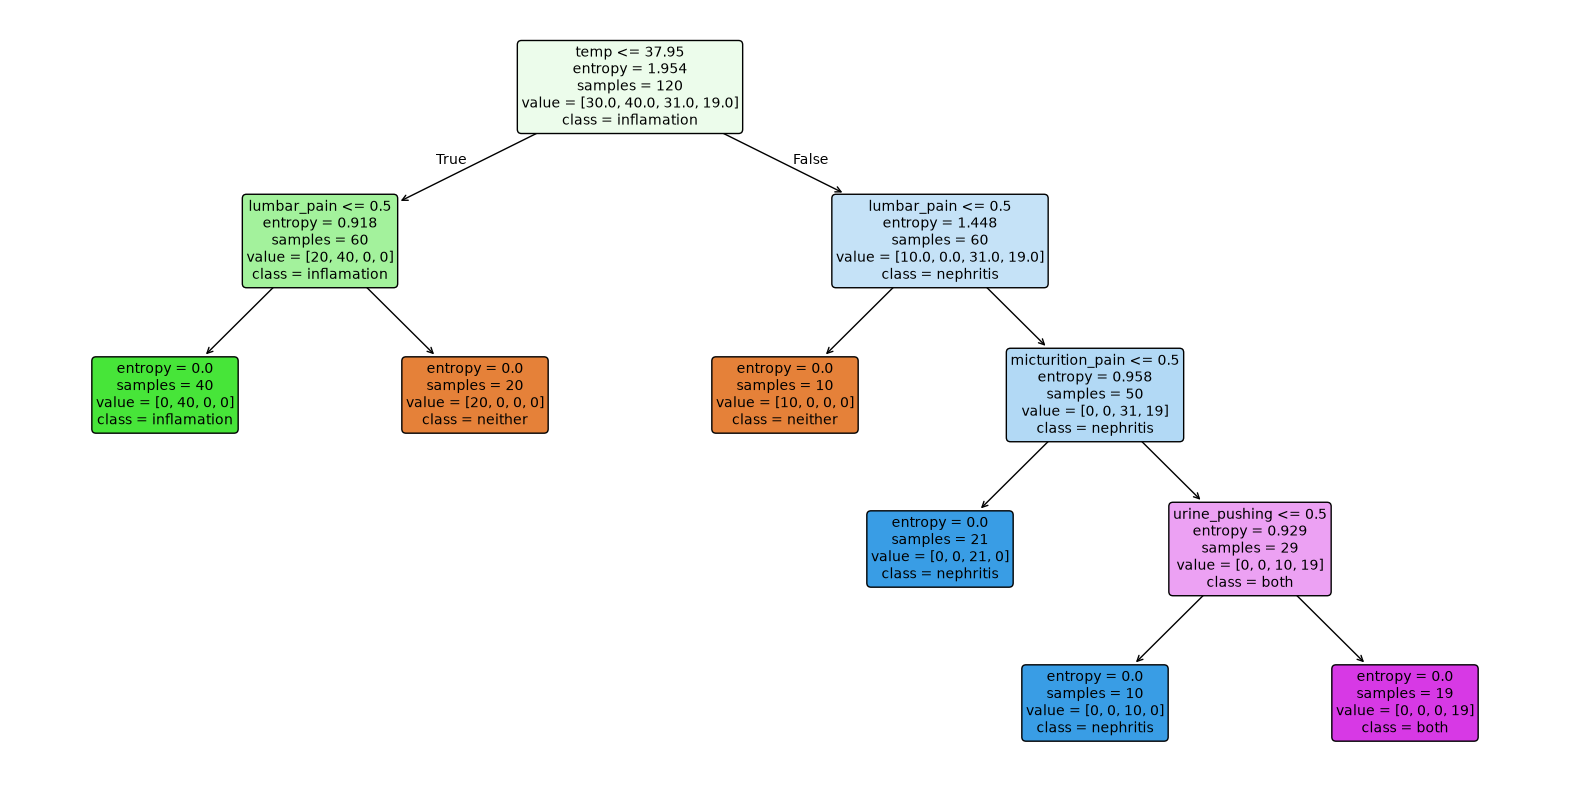

In [6]:
plt.figure(figsize=(20, 10))
plot_tree(
    full_tree,
    feature_names=X.columns,
    class_names=["neither", "inflamation", "nephritis", "both"],
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.show()

#### c)

In [7]:
def descision_tree_if_then(x):
    if x["temp"] <= 37.95:
        if x["lumbar_pain"]:
            return "neither"
        else:
            return "inflamation"
    else:
        if x["lumbar_pain"]:
            if x["micturition_pain"] and x["urine_pushing"]:
                return "both"
            else:
                return "nephritis"
        else:
            return "neither"

#### d)

In [8]:
alphas = np.arange(0, 1, 0.025)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=552)

mean_scores = []
standard_errors = []

for alpha in alphas:
    tree = DecisionTreeClassifier(
        criterion="entropy", ccp_alpha=alpha, random_state=552
    )

    scores = cross_val_score(tree, X, y, cv=cv)
    mean_scores.append(scores.mean())
    standard_errors.append(scores.std(ddof=1) / np.sqrt(cv.get_n_splits()))

summary = pd.DataFrame(
    {"ccp_alpha": alphas, "cv_accuracy": mean_scores, "standard_error": standard_errors}
)

summary

,ccp_alpha,cv_accuracy,standard_error
0,0.000,1.000000,0.000000e+00
1,0.025,1.000000,0.000000e+00
2,0.050,1.000000,0.000000e+00
3,0.075,1.000000,0.000000e+00
4,0.100,1.000000,0.000000e+00
5,0.125,1.000000,0.000000e+00
6,0.150,1.000000,0.000000e+00
7,0.175,1.000000,0.000000e+00
8,0.200,0.850000,1.666667e-02
9,0.225,0.841667,8.333333e-03


In [9]:
pruned_tree = DecisionTreeClassifier(
    criterion="entropy", random_state=552, ccp_alpha=0.175
)
pruned_tree.fit(X, y)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",552
,"ccp_alpha ccp_alpha: non-negative float, default=0.0Complexity parameter used for Minimal Cost-Complexity Pruning. Thesubtree with the largest cost complexity that is smaller than``ccp_alpha`` will be chosen. By default, no pruning is performed. See:ref:`minimal_cost_complexity_pruning` for details. See:ref:`sphx_glr_auto_examples_tree_plot_cost_complexity_pruning.py`for an example of such pruning... versionadded:: 0.22",0.175
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"mi

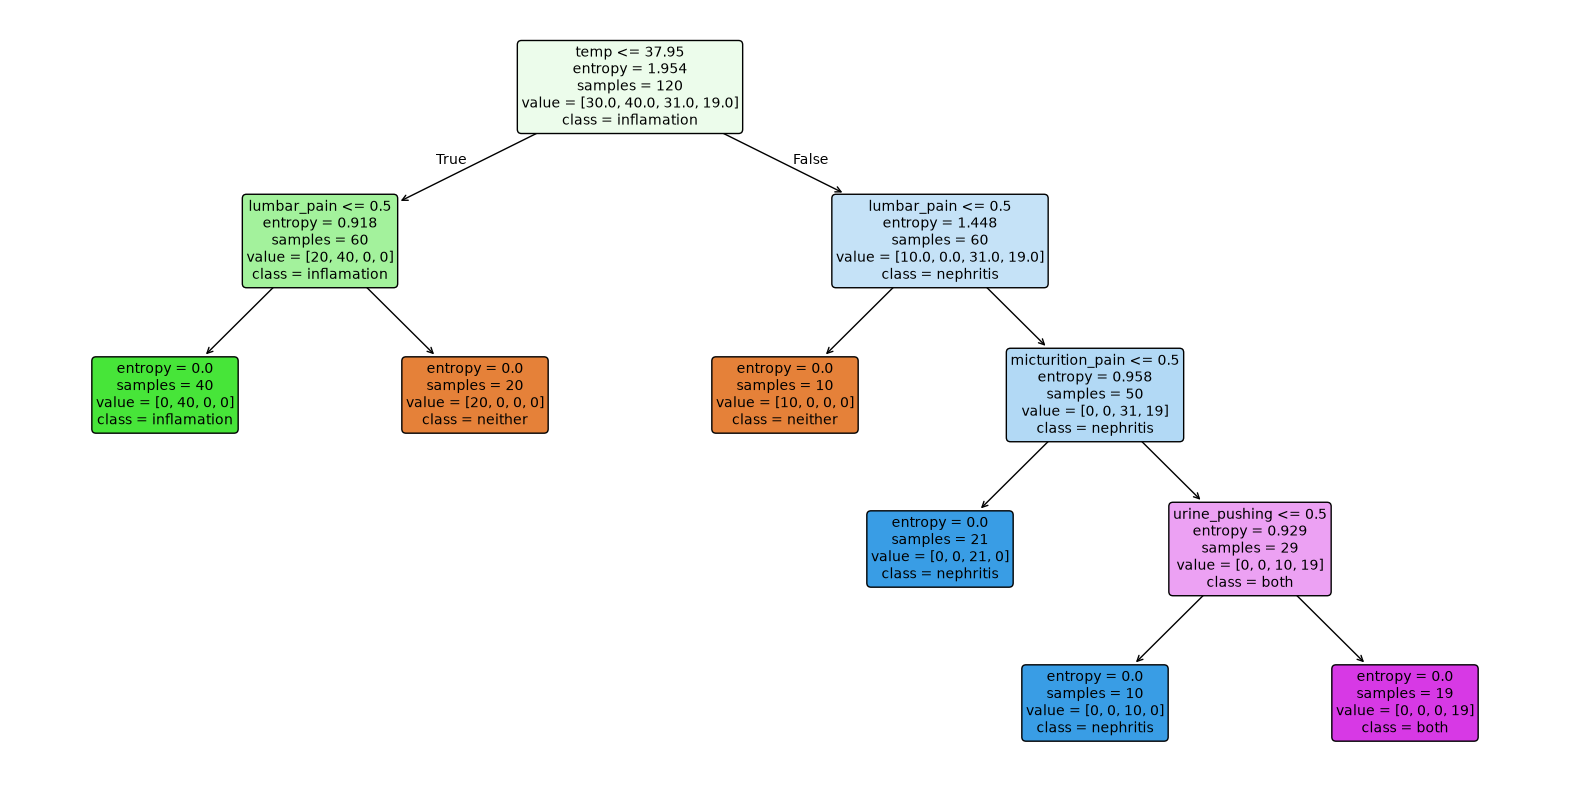

In [10]:
plt.figure(figsize=(20, 10))
plot_tree(
    pruned_tree,
    feature_names=X.columns,
    class_names=["neither", "inflamation", "nephritis", "both"],
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.show()

So the minimal tree is the full tree in this case.

### 2)

#### a)

In [11]:
names_text = Path("../data/communities.names").read_text()

columns = re.findall(
    r"^@attribute\s+(\S+)\s+", names_text, flags=re.MULTILINE | re.IGNORECASE
)

print(len(columns))

128


In [12]:
df = pd.read_csv("../data/communities.data", header=None, names=columns, na_values="?")
df = df[df.columns[5:]]
df

,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,...,0.12,0.26,0.20,0.06,0.04,0.90,0.5,0.32,0.14,0.20
1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1989,0.01,0.40,0.10,0.87,0.12,0.16,0.43,0.51,0.35,0.30,...,0.01,0.28,0.05,NaN,NaN,NaN,NaN,0.00,NaN,0.09
1990,0.05,0.96,0.46,0.28,0.83,0.32,0.69,0.86,0.73,0.14,...,0.02,0.37,0.20,NaN,NaN,NaN,NaN,0.00,NaN,0.45
1991,0.16,0.37,0.25,0.69,0.04,0.25,0.35,0.50,0.31,0.54,...,0.08,0.32,0.18,0.08,0.06,0.78,0.0,0.91,0.28,0.23
1992,0.08,0.51,0.06,0.87,0.22,0.10,0.58,0.74,0.63,0.41,...,0.03,0.38,0.33,0.02,0.02,0.79,0.0,0.22,0.18,0.19


In [13]:
train_df = df.iloc[:1495]
test_df = df.iloc[1495:]

X_train, y_train = train_df[train_df.columns[:-1]], train_df[train_df.columns[-1]]
X_test, y_test = test_df[train_df.columns[:-1]], test_df[train_df.columns[-1]]

#### b)

In [14]:
imputer = IterativeImputer(max_iter=10, random_state=552, initial_strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_train_imputed

/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-5/.venv/lib/python3.12/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


array([[0.19      , 0.33      , 0.02      , ..., 0.5       , 0.32      ,
        0.14      ],
       [0.        , 0.16      , 0.12      , ..., 0.62330296, 0.        ,
        0.20632146],
       [0.        , 0.42      , 0.49      , ..., 0.50006495, 0.        ,
        0.27775398],
       ...,
       [0.01      , 0.36      , 0.95      , ..., 0.52685197, 0.        ,
        0.1559813 ],
       [0.06      , 0.53      , 0.01      , ..., 0.36232785, 0.        ,
        0.22017503],
       [0.05      , 0.43      , 0.08      , ..., 0.        , 0.51      ,
        0.18      ]], shape=(1495, 122))

#### c)

In [15]:
X_train_imputed_df = pd.DataFrame(X_train_imputed, columns=X_train.columns)
X_train_imputed_df

,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,...,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop
0,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,...,0.290000,0.12,0.26,0.20,0.060000,0.040000,0.900000,0.500000,0.32,0.140000
1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,...,0.316236,0.02,0.12,0.45,0.012168,0.004749,0.725070,0.623303,0.00,0.206321
2,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,...,0.271564,0.01,0.21,0.02,0.081613,-0.041719,0.698557,0.500065,0.00,0.277754
3,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,...,0.240483,0.02,0.39,0.28,0.070984,0.047038,0.656555,0.425856,0.00,0.222087
4,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,...,0.223986,0.04,0.09,0.02,0.026525,0.010742,0.717677,0.329836,0.00,0.163051
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1490,0.00,0.59,0.01,0.69,1.00,0.07,0.41,0.28,0.23,0.57,...,0.412543,0.02,0.14,0.22,-0.039281,-0.020262,0.731863,0.365191,0.00,0.174691
1491,0.16,0.62,0.03,0.74,0.48,0.42,0.44,0.57,0.40,0.25,...,0.380000,0.07,0.40,0.14,0.070000,0.050000,0.850000,0.500000,0.61,0.190000
1492,0.01,0.36,0.95,0.24,0.03,0.01,0.44,0.42,0.27,0.63,...,0.250694,0.03,0.12,0.01,0.080825,-0.038476,0.621003,0.526852,0.00,0.155981
1493,0.06,0.53,0.01,0.98,0.05,0.01,0.40,0.40,0.24,0.29,...,0.256240,0.08,0.15,0.02,0.060673,0.102179,0.720934,0.362328,0.00,0.220175


In [16]:
def plot_correlation_heatmap(df, figsize=(16, 12)):
    corr = df.corr(numeric_only=True)

    plt.figure(figsize=figsize)
    sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
    plt.title("Feature Correlation Heatmap")
    plt.show()

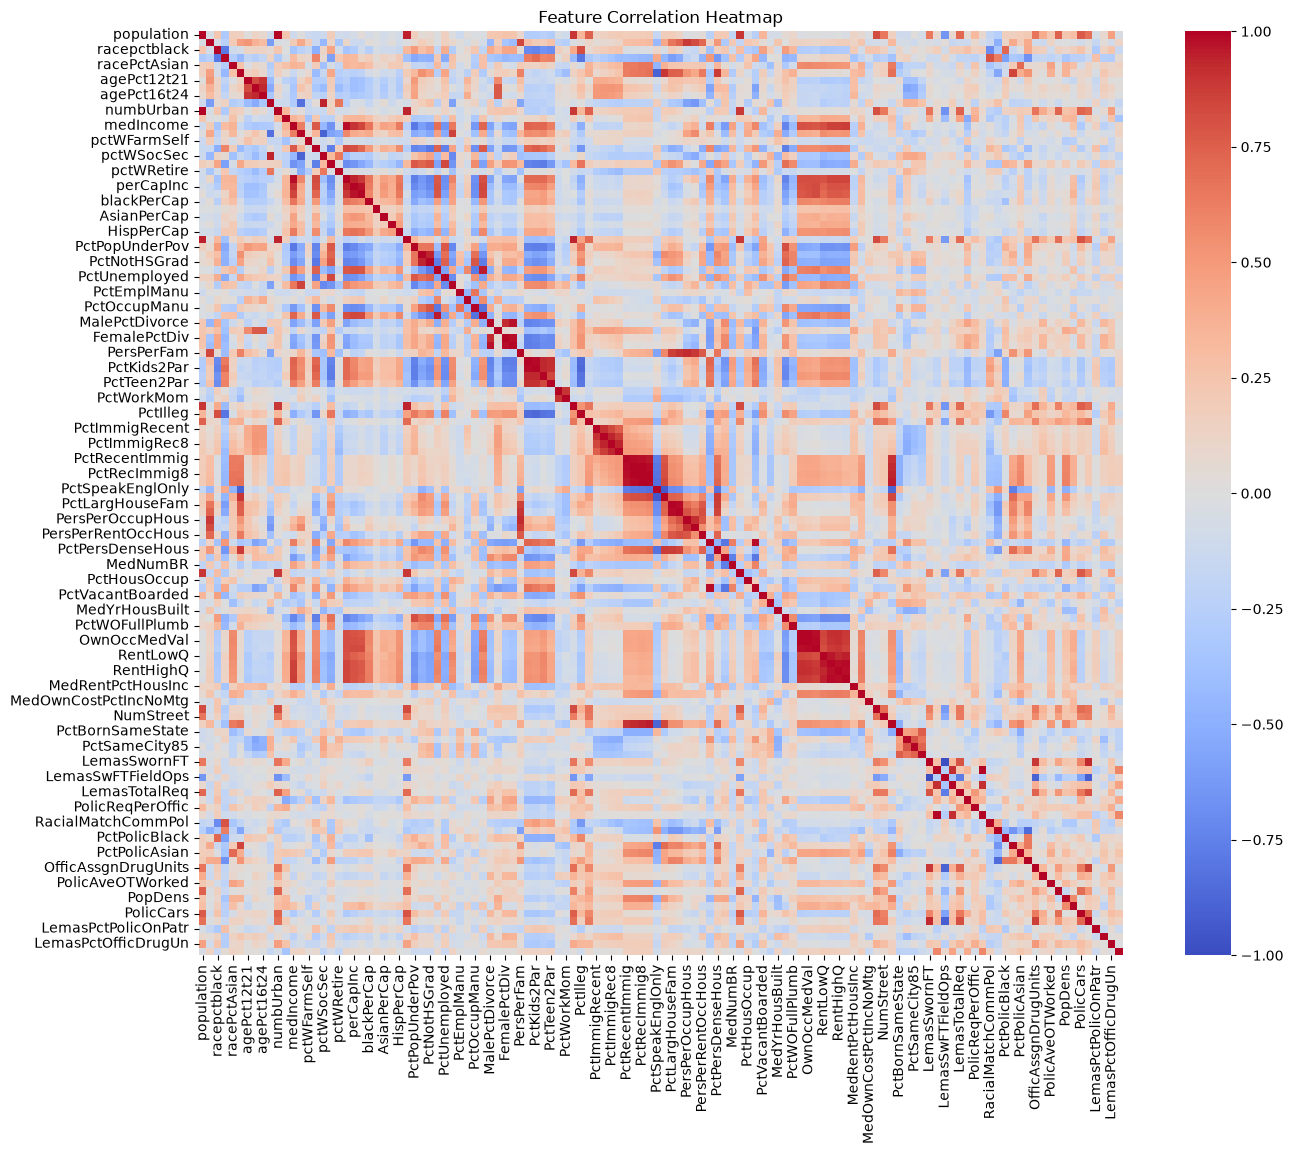

In [17]:
plot_correlation_heatmap(X_train_imputed_df)

#### d)

In [18]:
CV = X_train_imputed_df.std() / X_train_imputed_df.mean()
CV = CV.sort_values(ascending=False)
CV.head(20)

LemasTotalReq          10.828248
LemasSwornFT            6.974521
NumStreet               4.292923
NumInShelters           3.470952
NumIlleg                3.058964
NumImmig                2.926635
LemasPctOfficDrugUn     2.552946
NumUnderPov             2.342443
PolicOperBudg           2.267959
population              2.241105
PctPolicAsian           2.198796
numbUrban               2.038461
HousVacant              1.968467
LandArea                1.645408
racePctHisp             1.612091
PolicCars               1.545593
PctPolicHisp            1.492703
PctNotSpeakEnglWell     1.456618
racepctblack            1.428885
PctUsePubTrans          1.397110
dtype: float64

#### e)

In [19]:
p = int(np.floor(np.sqrt(128)))
p

11

In [20]:
features = list(CV.iloc[:p].index)
features

['LemasTotalReq',
 'LemasSwornFT',
 'NumStreet',
 'NumInShelters',
 'NumIlleg',
 'NumImmig',
 'LemasPctOfficDrugUn',
 'NumUnderPov',
 'PolicOperBudg',
 'population',
 'PctPolicAsian']

In [21]:
def plot_feature_pairs(df, target_col):
    feature_cols = df.drop(columns=target_col).select_dtypes(include="number").columns

    n_features = len(feature_cols)
    norm = mpl.colors.Normalize(vmin=df[target_col].min(), vmax=df[target_col].max())

    fig, axes = plt.subplots(
        n_features,
        n_features,
        figsize=(2.3 * n_features + 1.5, 2.3 * n_features),
        squeeze=False,
        layout="constrained",
    )

    for row, y_col in enumerate(feature_cols):
        for col, x_col in enumerate(feature_cols):
            ax = axes[row, col]

            if row == col:
                ax.text(
                    0.5,
                    0.5,
                    x_col,
                    ha="center",
                    va="center",
                    fontsize=8,
                    fontweight="bold",
                    wrap=True,
                    transform=ax.transAxes,
                )
                ax.set_xticks([])
                ax.set_yticks([])

            else:
                plot_data = df[[x_col, y_col, target_col]].dropna()

                ax.scatter(
                    plot_data[x_col],
                    plot_data[y_col],
                    c=plot_data[target_col],
                    cmap="viridis",
                    norm=norm,
                    alpha=0.7,
                    s=8,
                )
                ax.tick_params(labelsize=6)

            if row == n_features - 1:
                ax.set_xlabel(x_col, fontsize=7)

            if col == 0:
                ax.set_ylabel(y_col, fontsize=7)

    colorbar = fig.colorbar(
        mpl.cm.ScalarMappable(norm=norm, cmap="viridis"),
        ax=axes.ravel().tolist(),
        shrink=0.8,
        pad=0.01,
    )
    colorbar.set_label(target_col)

    plt.show()


def plot_feature_boxplots(df, ncols=4):
    features = df.columns
    nrows = math.ceil(len(features) / ncols)

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(4 * ncols, 4 * nrows), squeeze=False
    )
    axes = axes.flatten()

    for ax, feature in zip(axes, features):
        ax.boxplot(df[feature].dropna())
        ax.set_title(feature)
        ax.set_ylabel("Value")

    for ax in axes[len(features) :]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()

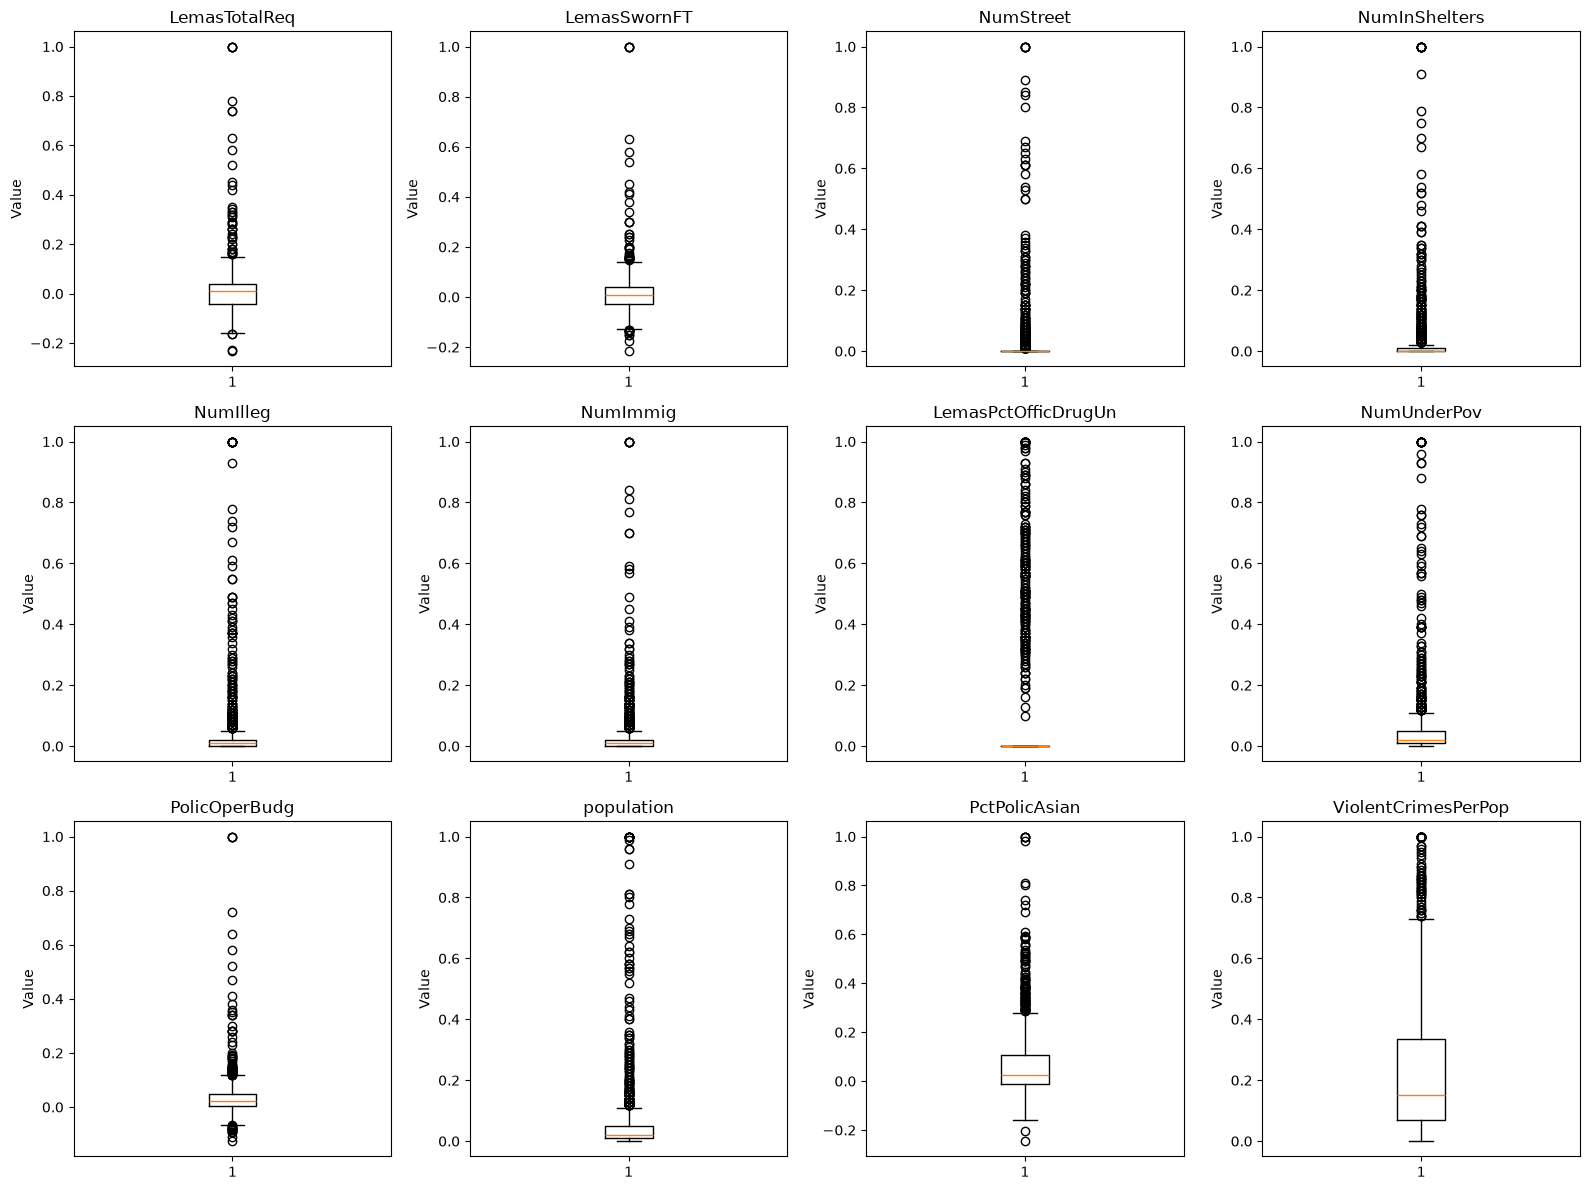

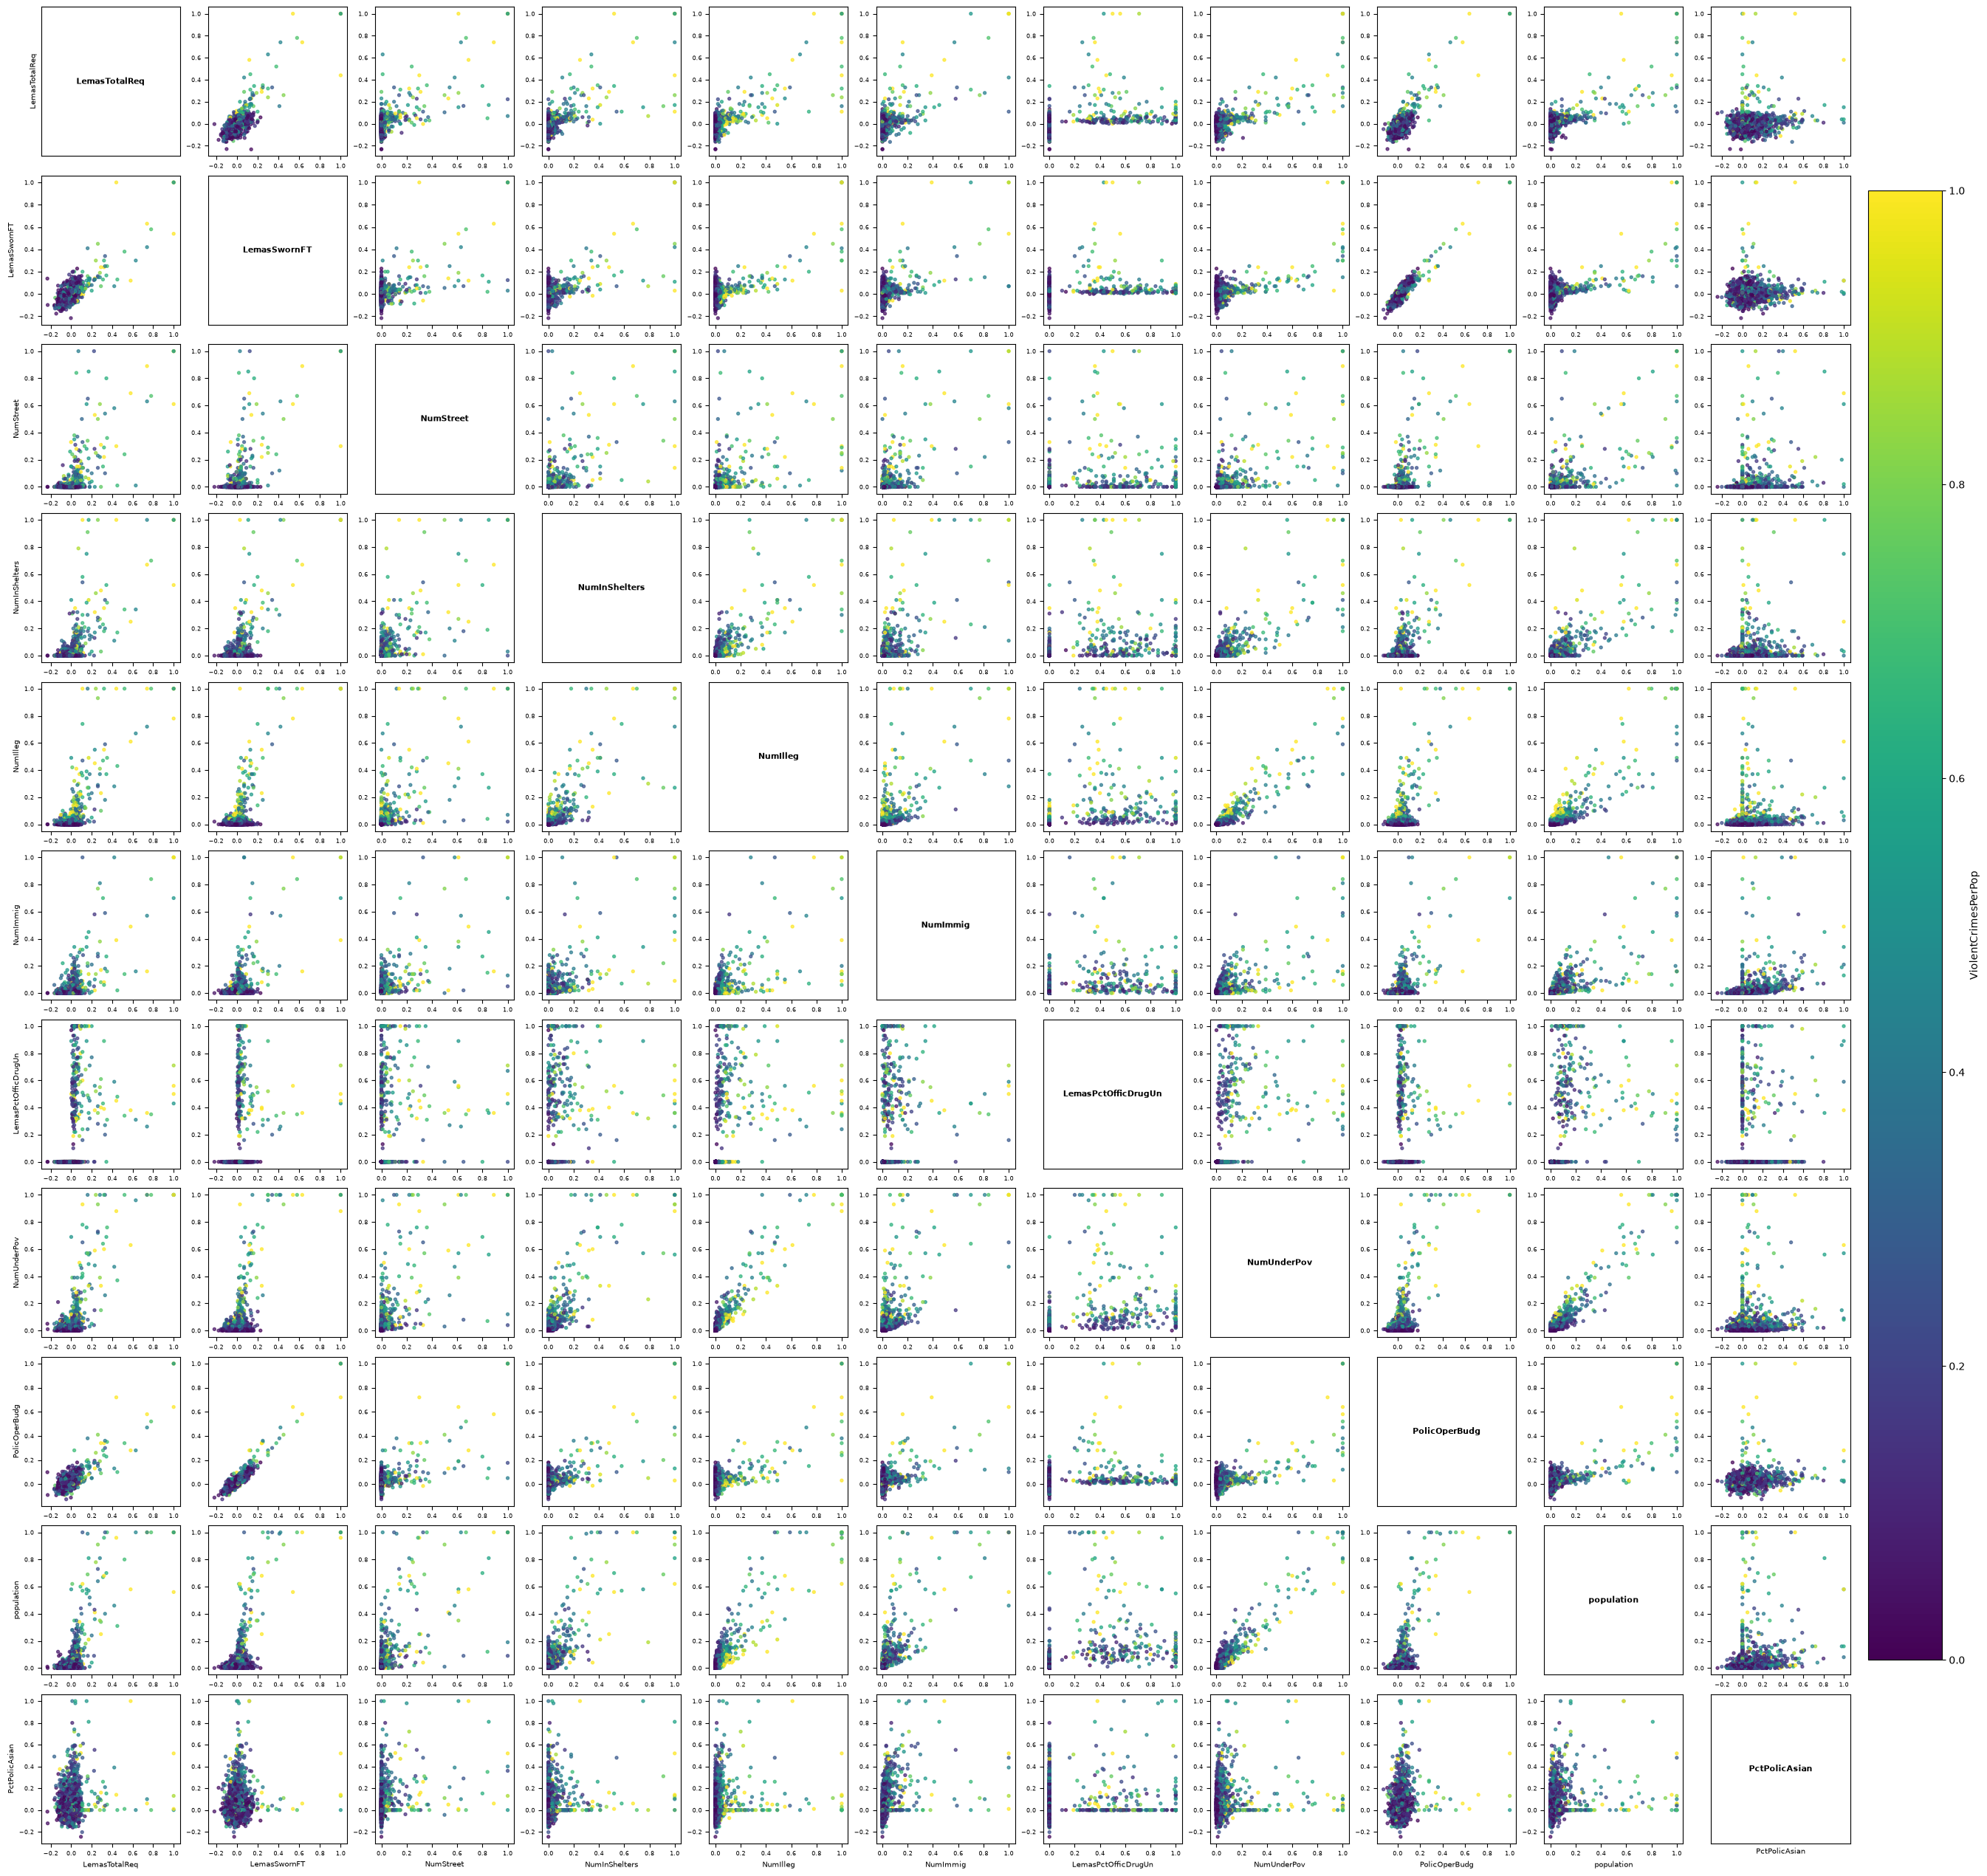

In [22]:
X_train_imputed_df_plotting = X_train_imputed_df.copy()
X_train_imputed_df_plotting["ViolentCrimesPerPop"] = y_train
X_train_imputed_df_plotting = X_train_imputed_df_plotting[
    features + ["ViolentCrimesPerPop"]
]
plot_feature_boxplots(X_train_imputed_df_plotting)
plot_feature_pairs(X_train_imputed_df_plotting, "ViolentCrimesPerPop")

It appears like these features have a ton of outliers (extreme values) which is intentional based on the CV selection criteria. But in the scatter plot, a lot of those spread out points seem to coincide with higher values of the dependent variable so these extrene points might have good prediction power.

#### f)

In [23]:
ols = LinearRegression()
ols.fit(X_train_imputed_df, y_train)
ols

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](122,)","[ 0.01,-0.01, 0.28,..., 0.04,-0.02,-0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](122,)","['population','householdsize','racepctblack',...,'LemasGangUnitDeploy', 'LemasPctOfficDrugUn','PolicBudgPerPop']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.5334
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,122
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(121)


In [24]:
X_test_imputed = imputer.transform(X_test)
X_test_imputed_df = pd.DataFrame(X_test_imputed, columns=X_test.columns)
X_test_imputed_df

,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,...,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop
0,0.00,0.20,0.03,0.91,0.23,0.05,0.15,0.19,0.09,0.42,...,0.385906,0.01,0.23,0.73,-0.006036,-0.017654,0.769984,0.481819,0.00,0.293943
1,0.00,0.55,0.13,0.78,0.15,0.36,0.48,0.53,0.30,0.10,...,0.205564,0.01,0.18,0.02,0.050930,0.080400,0.711485,0.410295,0.00,0.117901
2,0.00,0.52,0.04,0.59,0.05,0.62,0.84,0.78,0.75,0.43,...,0.304960,0.01,0.18,0.00,0.096820,0.051304,0.753649,0.564643,0.00,0.145257
3,0.04,0.51,0.07,0.92,0.09,0.03,0.38,0.47,0.27,0.35,...,0.260332,0.06,0.13,0.16,0.029887,0.041264,0.717659,0.356021,0.00,0.175793
4,0.03,0.59,0.20,0.75,0.19,0.10,0.38,0.62,0.35,0.11,...,0.242814,0.03,0.23,0.06,0.053084,0.024747,0.658790,0.487974,0.00,0.223784
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
494,0.01,0.40,0.10,0.87,0.12,0.16,0.43,0.51,0.35,0.30,...,0.260967,0.01,0.28,0.05,0.039151,0.011014,0.706730,0.499146,0.00,0.183750
495,0.05,0.96,0.46,0.28,0.83,0.32,0.69,0.86,0.73,0.14,...,0.384148,0.02,0.37,0.20,0.063557,0.042057,0.641890,0.583656,0.00,0.282863
496,0.16,0.37,0.25,0.69,0.04,0.25,0.35,0.50,0.31,0.54,...,0.250000,0.08,0.32,0.18,0.080000,0.060000,0.780000,0.000000,0.91,0.280000
497,0.08,0.51,0.06,0.87,0.22,0.10,0.58,0.74,0.63,0.41,...,0.190000,0.03,0.38,0.33,0.020000,0.020000,0.790000,0.000000,0.22,0.180000


In [25]:
y_pred = ols.predict(X_test_imputed_df)
mse = mean_squared_error(y_test, y_pred)

print(f"OLS Test MSE: {mse}")

OLS Test MSE: 0.01802715174775715


#### g)

In [26]:
alphas = [10**k for k in range(-5, 6)]
cv = KFold(n_splits=5, shuffle=True, random_state=552)

results = []

for alpha in tqdm(alphas):
    model = Ridge(alpha=alpha)

    mse_scores = -cross_val_score(
        model, X_train_imputed_df, y_train, cv=cv, scoring="neg_mean_squared_error"
    )

    results.append({"alpha": alpha, "mse": mse_scores.mean()})

results_df = pd.DataFrame(results)
results_df

100%|██████████| 11/11 [00:00<00:00, 96.73it/s]


,alpha,mse
0,0.00001,0.020363
1,0.00010,0.020359
2,0.00100,0.020318
3,0.01000,0.020111
4,0.10000,0.019620
5,1.00000,0.019046
6,10.00000,0.019143
7,100.00000,0.020437
8,1000.00000,0.030963
9,10000.00000,0.050348


In [27]:
alpha_star = results_df.sort_values("mse", ascending=True)["alpha"].iloc[0]
alpha_star

np.float64(1.0)

In [28]:
ridge = Ridge(alpha=alpha_star)
ridge.fit(X_train_imputed_df, y_train)
ridge

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",np.float64(1.0)
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag

In [29]:
y_pred = ridge.predict(X_test_imputed_df)
mse = mean_squared_error(y_test, y_pred)

print(f"Ridge Test MSE: {mse}")

Ridge Test MSE: 0.01771978081166733


#### h)

In [30]:
alphas = [10**k for k in range(-5, 6)]
cv = KFold(n_splits=5, shuffle=True, random_state=552)

results = []

for alpha in tqdm(alphas):
    model = Lasso(alpha=alpha, max_iter=10000)

    mse_scores = -cross_val_score(
        model, X_train_imputed_df, y_train, cv=cv, scoring="neg_mean_squared_error"
    )

    results.append({"alpha": alpha, "mse": mse_scores.mean()})

results_df = pd.DataFrame(results)
results_df

100%|██████████| 11/11 [00:01<00:00, 10.23it/s]


,alpha,mse
0,0.00001,0.019748
1,0.00010,0.019030
2,0.00100,0.019522
3,0.01000,0.024470
4,0.10000,0.056566
5,1.00000,0.056566
6,10.00000,0.056566
7,100.00000,0.056566
8,1000.00000,0.056566
9,10000.00000,0.056566


In [31]:
alpha_star = results_df.sort_values("mse", ascending=True)["alpha"].iloc[0]
alpha_star

np.float64(0.0001)

In [32]:
lasso = Lasso(alpha=alpha_star)
lasso.fit(X_train_imputed_df, y_train)
lasso

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",np.float64(0.0001)
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [33]:
y_pred = lasso.predict(X_test_imputed_df)
mse = mean_squared_error(y_test, y_pred)

print(f"Lasso Test MSE: {mse}")


Lasso Test MSE: 0.017894855239129773


In [34]:
selected_cols = [
    X_train.columns[i] for i, selected in enumerate(list(lasso.coef_ != 0)) if selected
]
len(selected_cols)

77

In [35]:
selected_cols

['racepctblack',
 'racePctAsian',
 'racePctHisp',
 'agePct12t21',
 'agePct12t29',
 'agePct65up',
 'pctUrban',
 'pctWWage',
 'pctWFarmSelf',
 'pctWInvInc',
 'pctWSocSec',
 'pctWPubAsst',
 'pctWRetire',
 'whitePerCap',
 'blackPerCap',
 'indianPerCap',
 'AsianPerCap',
 'OtherPerCap',
 'HispPerCap',
 'PctPopUnderPov',
 'PctLess9thGrade',
 'PctEmploy',
 'PctEmplManu',
 'PctEmplProfServ',
 'PctOccupManu',
 'MalePctDivorce',
 'MalePctNevMarr',
 'FemalePctDiv',
 'PctKids2Par',
 'PctYoungKids2Par',
 'PctTeen2Par',
 'PctWorkMom',
 'NumIlleg',
 'PctIlleg',
 'NumImmig',
 'PctImmigRecent',
 'PctImmigRec10',
 'PctRecImmig10',
 'PctNotSpeakEnglWell',
 'PctLargHouseOccup',
 'PersPerOccupHous',
 'PctPersOwnOccup',
 'PctPersDenseHous',
 'PctHousLess3BR',
 'MedNumBR',
 'HousVacant',
 'PctHousOccup',
 'PctVacantBoarded',
 'PctVacMore6Mos',
 'MedYrHousBuilt',
 'PctHousNoPhone',
 'PctWOFullPlumb',
 'OwnOccLowQuart',
 'RentLowQ',
 'MedRent',
 'MedRentPctHousInc',
 'MedOwnCostPctInc',
 'MedOwnCostPctIncNoMtg'

In [36]:
alphas = [10**k for k in range(-5, 6)]
cv = KFold(n_splits=5, shuffle=True, random_state=552)

results = []

for alpha in tqdm(alphas):
    model = Pipeline(
        [
            ("scaler", StandardScaler()),
            ("lasso", Lasso(alpha=alpha, max_iter=10000)),
        ]
    )

    mse_scores = -cross_val_score(
        model, X_train_imputed_df, y_train, cv=cv, scoring="neg_mean_squared_error"
    )

    results.append({"alpha": alpha, "mse": mse_scores.mean()})

results_df = pd.DataFrame(results)
results_df

100%|██████████| 11/11 [00:02<00:00,  4.30it/s]


,alpha,mse
0,0.00001,0.020235
1,0.00010,0.019677
2,0.00100,0.019167
3,0.01000,0.019914
4,0.10000,0.033858
5,1.00000,0.056566
6,10.00000,0.056566
7,100.00000,0.056566
8,1000.00000,0.056566
9,10000.00000,0.056566


In [37]:
alpha_star = results_df.sort_values("mse", ascending=True)["alpha"].iloc[0]
alpha_star

np.float64(0.001)

In [38]:
model = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("lasso", Lasso(alpha=alpha_star)),
    ]
)
model.fit(X_train_imputed_df, y_train)
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('lasso', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](122,)","['population','householdsize','racepctblack',...,'LemasGangUnitDeploy', 'LemasPctOfficDrugUn','PolicBudgPerPop']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,122
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [39]:
y_pred = model.predict(X_test_imputed_df)
mse = mean_squared_error(y_test, y_pred)

print(f"Scalar + Lasso Test MSE: {mse}")


Scalar + Lasso Test MSE: 0.01783849796545341


In [40]:
selected_cols = [
    X_train.columns[i]
    for i, selected in enumerate(list(model["lasso"].coef_ != 0))
    if selected
]
len(selected_cols)

66

In [41]:
selected_cols

['racepctblack',
 'racePctAsian',
 'agePct12t21',
 'agePct12t29',
 'pctUrban',
 'pctWWage',
 'pctWFarmSelf',
 'pctWInvInc',
 'pctWSocSec',
 'pctWPubAsst',
 'pctWRetire',
 'whitePerCap',
 'blackPerCap',
 'indianPerCap',
 'AsianPerCap',
 'OtherPerCap',
 'HispPerCap',
 'PctPopUnderPov',
 'PctEmploy',
 'PctEmplManu',
 'MalePctDivorce',
 'MalePctNevMarr',
 'FemalePctDiv',
 'PctKids2Par',
 'PctYoungKids2Par',
 'PctTeen2Par',
 'PctWorkMom',
 'NumIlleg',
 'PctIlleg',
 'NumImmig',
 'PctImmigRec10',
 'PctRecImmig10',
 'PctNotSpeakEnglWell',
 'PctLargHouseOccup',
 'PctPersOwnOccup',
 'PctPersDenseHous',
 'PctHousLess3BR',
 'HousVacant',
 'PctHousOccup',
 'PctVacantBoarded',
 'PctVacMore6Mos',
 'MedYrHousBuilt',
 'PctWOFullPlumb',
 'RentLowQ',
 'MedRent',
 'MedRentPctHousInc',
 'MedOwnCostPctInc',
 'MedOwnCostPctIncNoMtg',
 'NumInShelters',
 'NumStreet',
 'PctSameCity85',
 'LemasSwFTPerPop',
 'LemasSwFTFieldOps',
 'PolicReqPerOffic',
 'PolicPerPop',
 'RacialMatchCommPol',
 'PctPolicMinor',
 'Offic

#### i)

In [42]:
Ms = list(range(1, 25))
cv = KFold(n_splits=5, shuffle=True, random_state=552)

results = []

for M in tqdm(Ms):
    model = Pipeline(
        [
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=M)),
            ("linear_regression", LinearRegression()),
        ]
    )

    mse_scores = -cross_val_score(
        model, X_train_imputed_df, y_train, cv=cv, scoring="neg_mean_squared_error"
    )

    results.append({"M": M, "mse": mse_scores.mean()})

results_df = pd.DataFrame(results)
results_df

100%|██████████| 24/24 [00:00<00:00, 40.41it/s]


,M,mse
0,1,0.031369
1,2,0.028271
2,3,0.027181
3,4,0.026831
4,5,0.025454
5,6,0.024596
6,7,0.020809
7,8,0.020762
8,9,0.020640
9,10,0.020472


In [43]:
M_star = results_df.sort_values("mse", ascending=True)["M"].iloc[0]
M_star

np.int64(11)

In [44]:
pcr = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=M_star)),
        ("linear_regression", LinearRegression()),
    ]
)
pcr.fit(X_train_imputed_df, y_train)
pcr

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('pca', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](122,)","['population','householdsize','racepctblack',...,'LemasGangUnitDeploy', 'LemasPctOfficDrugUn','PolicBudgPerPop']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,122
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [45]:
y_pred = pcr.predict(X_test_imputed_df)
mse = mean_squared_error(y_test, y_pred)

print(f"PCR MSE: {mse}")


PCR MSE: 0.018235754617657602


#### j)

In [46]:
# ChatGPT: Give me an example of a training loop for XGBoost with L1 Trees at each node
alphas = [10**k for k in range(-5, 6)]
cv = KFold(n_splits=5, shuffle=True, random_state=552)

results = []

for alpha in tqdm(alphas):
    xgb = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        reg_alpha=alpha,
        reg_lambda=0,
        random_state=552,
        n_jobs=-1,
        verbosity=0,
    )

    mse_scores = -cross_val_score(
        xgb,
        X_train_imputed_df,
        y_train,
        cv=cv,
        scoring="neg_mean_squared_error",
    )

    results.append(
        {
            "alpha": alpha,
            "mse": mse_scores.mean(),
        }
    )

results_df = pd.DataFrame(results).sort_values("mse")
results_df

100%|██████████| 11/11 [00:17<00:00,  1.62s/it]


,alpha,mse
5,1.00000,0.019924
4,0.10000,0.019984
3,0.01000,0.020225
2,0.00100,0.020289
1,0.00010,0.020360
0,0.00001,0.020412
6,10.00000,0.021334
7,100.00000,0.056566
8,1000.00000,0.056566
9,10000.00000,0.056566


In [47]:
alpha_star = results_df["alpha"].iloc[0]
alpha_star

np.float64(1.0)

In [48]:
xgb = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    reg_alpha=alpha_star,
    reg_lambda=0,
    random_state=552,
    n_jobs=-1,
    verbosity=0,
)

xgb.fit(X_train_imputed_df, y_train)
xgb

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [49]:
y_pred = xgb.predict(X_test_imputed_df)
mse = mean_squared_error(y_test, y_pred)

print(f"XGBoost: {mse}")

XGBoost: 0.01648004333743565


This model did the best out of all of them.